# 02 — Détection des ulves sur Sentinel-2 et calibration sur le CEVA

Produit par `scripts/detecter_s2.py` puis `scripts/calibrer_s2.py` (voir `configs/detection.yaml`).

**Méthode**
- Zone analysée : polygones des sites CEVA de la baie ∩ classes « sol nu » et « eau » d'ESA WorldCover 2021.
  Les prés salés (NDVI élevé toute l'année) et la terre sont ainsi exclus.
- Pixel valide : pas de nuage, d'ombre ni de cirrus (bande SCL). Ulve : NDVI > seuil.
- **Marée** : les ulves ne se voient qu'à marée basse. Pour chaque baie et chaque mois, on garde
  la scène claire où la surface émergée (NDWI ≤ 0) est la plus grande.
- Cumul « façon CEVA » : somme des scènes de mai, juillet et septembre, comparée au cumul CEVA.

In [1]:
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

RACINE = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
sys.path.insert(0, str(RACINE / "src"))
from algathon.detection import calibration as cal

P = RACINE / "data" / "processed"
scenes = pd.read_csv(P / "s2_scenes.csv")
mensuel = pd.read_csv(P / "s2_mensuel.csv")
annuel = pd.read_csv(P / "s2_annuel.csv")
ceva = pd.read_csv(P / "baies_annuel.csv")
baies = sorted(scenes["baie"].unique())
pd.set_option("display.precision", 2)
print(len(scenes), "scènes analysées ;", len(mensuel), "mois-baies avec une scène claire")

4881 scènes analysées ; 376 mois-baies avec une scène claire


## 1. Combien de scènes utilisables ?

In [2]:
s = scenes[scenes["zone_ha"] > 0].copy()
s["claire"] = s["valid_ha"] / s["zone_ha"] >= 0.9
s["annee"] = pd.to_datetime(s["date"]).dt.year
dispo = s.groupby("baie").agg(scenes=("id", "count"), claires=("claire", "sum"))
dispo["part_claires"] = dispo["claires"] / dispo["scenes"]
mois_ok = mensuel.groupby("baie").size().rename("mois_avec_scene")
mois_possibles = (mensuel["annee"].max() - mensuel["annee"].min() + 1) * 7
dispo = dispo.join(mois_ok)
dispo["part_mois_couverts"] = dispo["mois_avec_scene"] / mois_possibles
dispo

,scenes,claires,part_claires,mois_avec_scene,part_mois_couverts
baie,,,,,
concarneau_la_foret,917,221,0.24,62,0.89
douarnenez,880,74,0.08,39,0.56
fresnaye,458,113,0.25,58,0.83
guisseny,455,69,0.15,35,0.50
horn_guillec,875,272,0.31,56,0.80
lieue_de_greve,876,360,0.41,64,0.91
saint_brieuc,420,210,0.50,62,0.89


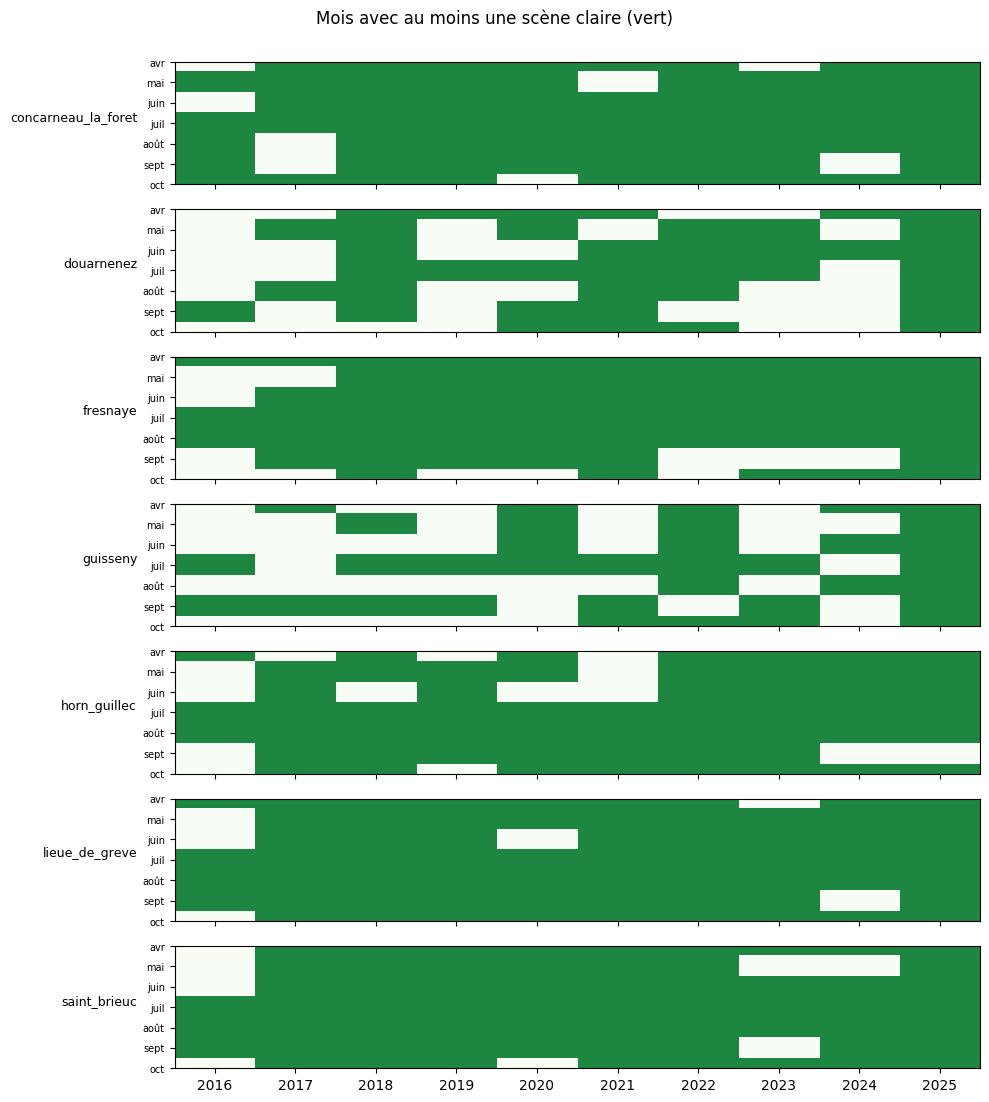

In [3]:
fig, axes = plt.subplots(len(baies), 1, figsize=(10, 1.6 * len(baies)), sharex=True)
annees = range(int(mensuel["annee"].min()), int(mensuel["annee"].max()) + 1)
for ax, b in zip(axes, baies):
    g = mensuel[mensuel["baie"] == b]
    grille = np.zeros((7, len(annees)))
    for _, r in g.iterrows():
        grille[int(r["mois"]) - 4, int(r["annee"]) - min(annees)] = 1
    ax.imshow(grille, aspect="auto", cmap="Greens", vmin=0, vmax=1.3)
    ax.set_yticks(range(7)); ax.set_yticklabels(["avr", "mai", "juin", "juil", "août", "sept", "oct"], fontsize=7)
    ax.set_ylabel(b, rotation=0, ha="right", fontsize=9)
axes[-1].set_xticks(range(len(annees))); axes[-1].set_xticklabels(annees)
fig.suptitle("Mois avec au moins une scène claire (vert)")
fig.tight_layout(rect=[0, 0, 1, 0.95])

## 2. L'effet de la marée

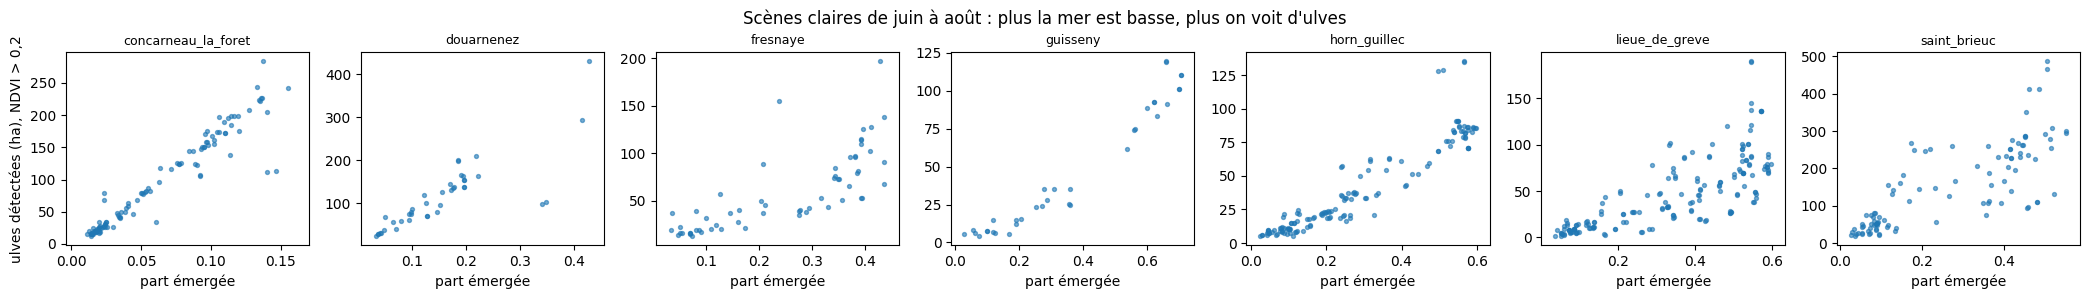

In [4]:
fig, axes = plt.subplots(1, len(baies), figsize=(3 * len(baies), 3), sharey=False)
c = "ulva_ha_s020"
for ax, b in zip(axes, baies):
    g = s[(s["baie"] == b) & s["claire"]]
    g = g[pd.to_datetime(g["date"]).dt.month.isin([6, 7, 8])]
    ax.scatter((g["valid_ha"] - g["eau_ha"]).values / g["zone_ha"].values, g[c].values, s=8, alpha=0.6)
    ax.set_title(b, fontsize=9); ax.set_xlabel("part émergée")
axes[0].set_ylabel("ulves détectées (ha), NDVI > 0,2")
fig.suptitle("Scènes claires de juin à août : plus la mer est basse, plus on voit d'ulves")
fig.tight_layout(rect=[0, 0, 1, 0.95])

## 3. Calibration : quel seuil NDVI suit le mieux le CEVA ?

In [5]:
cumuls = annuel.drop(columns=["surface_ha"])
comp = cal.comparer_ceva(cumuls, ceva)
comp

,seuil_ndvi,n,spearman_global,spearman_intra,n_baies_intra,ratio_median
0,0.10,29,0.52,0.23,5,3.54
1,0.15,29,0.43,0.27,5,2.10
2,0.20,29,0.42,0.35,5,1.53
3,0.25,29,0.41,0.38,5,1.06
4,0.30,29,0.33,0.40,5,0.76
5,0.40,29,0.22,0.42,5,0.43


In [6]:
# 0,2 : meilleur accord sur les baies sans faux positifs (Saint-Brieuc, Lieue de Grève)
meilleur = 0.20
col = "ulva_ha_s%03d" % round(meilleur * 100)
print("Seuil retenu :", meilleur)
cal.correlation_par_baie(cumuls, ceva, col)

Seuil retenu : 0.2


,n,spearman,ratio_median
baie,,,
concarneau_la_foret,5.0,-0.20,16.14
douarnenez,2.0,-1.00,3.30
fresnaye,4.0,0.20,1.92
guisseny,1.0,NaN,2.89
horn_guillec,5.0,0.30,1.81
lieue_de_greve,6.0,0.60,0.99
saint_brieuc,6.0,0.83,1.02


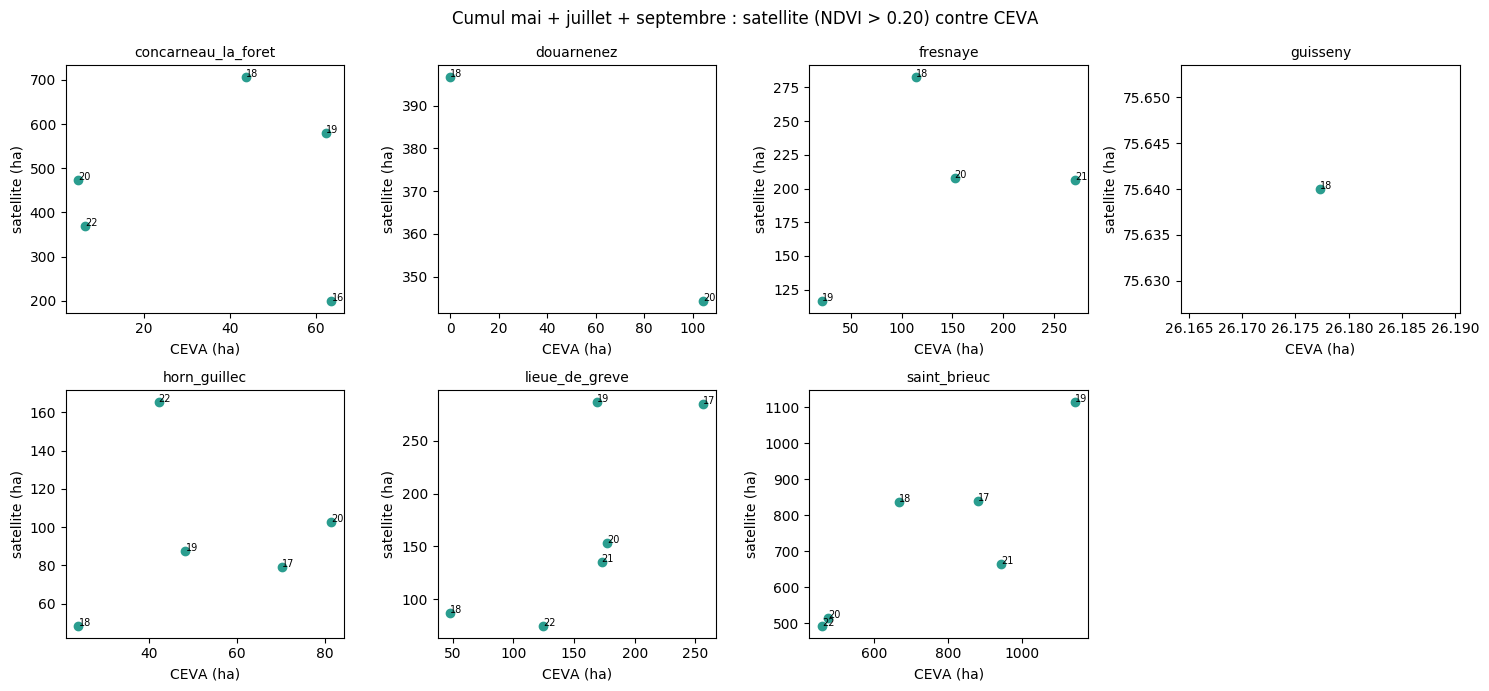

In [7]:
fig, axes = plt.subplots(2, 4, figsize=(15, 7))
for ax, b in zip(axes.flat, baies):
    g = annuel[(annuel["baie"] == b)].dropna(subset=[col])
    obs = g.dropna(subset=["surface_ha"])
    ax.scatter(obs["surface_ha"].values, obs[col].values, color="#2a9d8f")
    for _, r in obs.iterrows():
        ax.annotate(str(int(r["annee"]))[2:], (r["surface_ha"], r[col]), fontsize=7)
    ax.set_title(b, fontsize=10); ax.set_xlabel("CEVA (ha)"); ax.set_ylabel("satellite (ha)")
axes.flat[-1].axis("off")
fig.suptitle("Cumul mai + juillet + septembre : satellite (NDVI > %.2f) contre CEVA" % meilleur)
fig.tight_layout(rect=[0, 0, 1, 0.95])

## 4. Séries : CEVA jusqu'en 2022, satellite ensuite

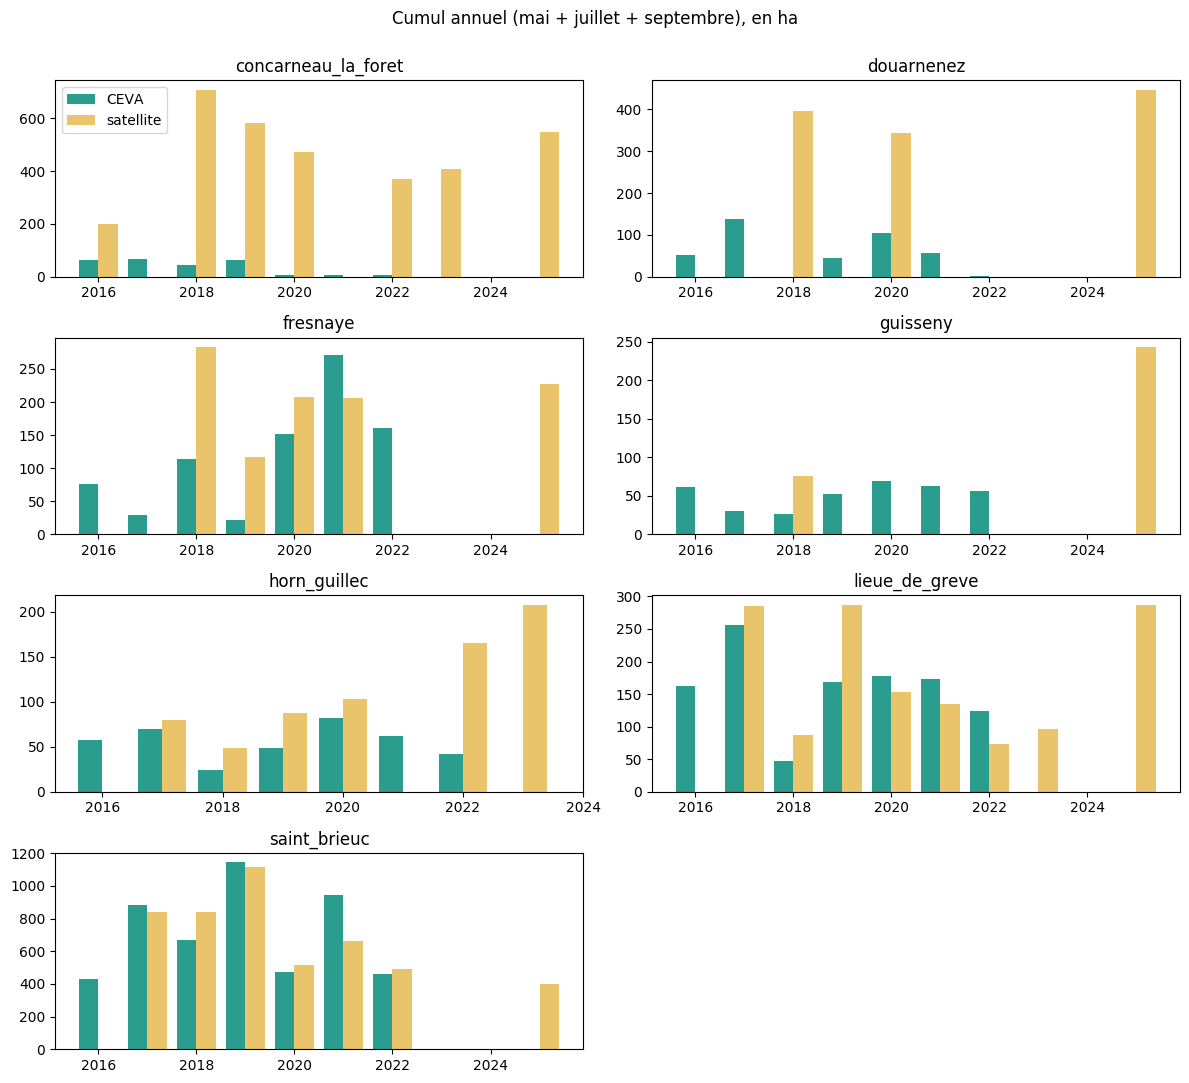

In [8]:
fig, axes = plt.subplots(4, 2, figsize=(12, 11))
for ax, b in zip(axes.flat, baies):
    g = annuel[annuel["baie"] == b].sort_values("annee")
    c0 = ceva[(ceva["baie"] == b) & (ceva["annee"] >= 2016)]
    ax.bar(c0["annee"].values - 0.2, c0["surface_ha"].values, width=0.4, color="#2a9d8f", label="CEVA")
    ax.bar(g["annee"].values + 0.2, g[col].values, width=0.4, color="#e9c46a", label="satellite")
    ax.set_title(b); ax.set_xticks(range(2016, 2026, 2))
axes.flat[-1].axis("off")
axes.flat[0].legend()
fig.suptitle("Cumul annuel (mai + juillet + septembre), en ha")
fig.tight_layout(rect=[0, 0, 1, 0.95])

## 5. Saisonnalité mensuelle vue par le satellite

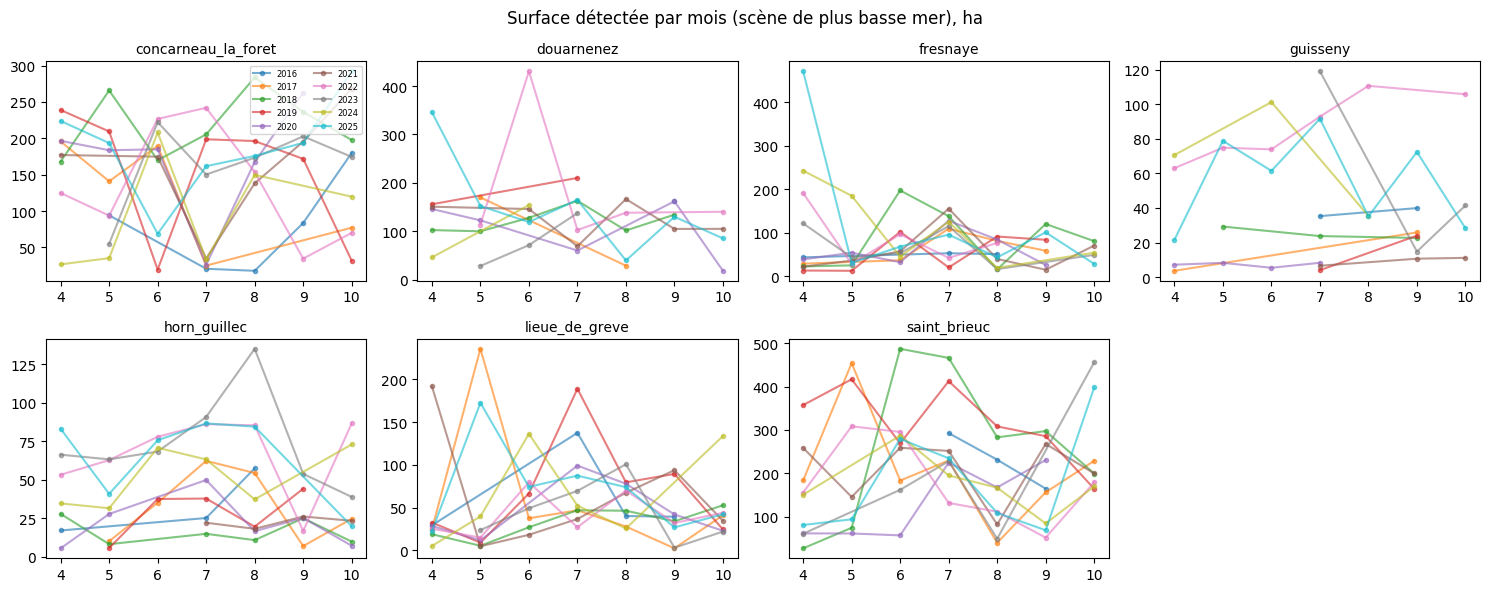

In [9]:
fig, axes = plt.subplots(2, 4, figsize=(15, 6))
for ax, b in zip(axes.flat, baies):
    g = mensuel[mensuel["baie"] == b]
    for a, ga in g.groupby("annee"):
        ax.plot(ga["mois"].values, ga[col].values, marker=".", alpha=0.6, label=str(a))
    ax.set_title(b, fontsize=10); ax.set_xticks(range(4, 11))
axes.flat[-1].axis("off")
axes.flat[0].legend(fontsize=6, ncol=2)
fig.suptitle("Surface détectée par mois (scène de plus basse mer), ha")
fig.tight_layout(rect=[0, 0, 1, 0.95])

## Ce qu'on retient

- **La méthode fonctionne sur les grandes baies sableuses.** À Saint-Brieuc (Spearman 0,83 sur 6 années) et en Lieue de Grève (0,60), le cumul satellite au seuil NDVI 0,2 est du même ordre que le CEVA (rapport médian ≈ 1,0) et suit les bonnes et les mauvaises années.
- **La marée est décisive** : à quelques jours d'écart, la surface détectée varie du simple au triple selon la part émergée. Choisir la scène de plus basse mer est indispensable.
- **Faux positifs à Concarneau-La Forêt (×16) et Douarnenez (×3,3).** Les détections suivent les côtes rocheuses (algues brunes fixées, pixels mixtes terre/mer) et, à Douarnenez, une bande dans l'eau (ulves en suspension ou herbiers). WorldCover ne sépare pas roche et sable. Il faut un masque de **végétation permanente** (pixels détectés dans la plupart des scènes de basse mer, toutes saisons) et une érosion de la zone le long du trait de côte.
- **Peu d'années complètes** : exiger une scène claire en mai, juillet et septembre ne laisse que 29 couples baie-année comparables au CEVA (2016-2022). Une tolérance de ± 15 jours autour des mois des survols en récupérerait.
- **Cible CEVA à vérifier** : Douarnenez vaut 0 ha en 2018 (tous les sites), Fresnaye 0 ha de 2010 à 2014. Ces zéros ressemblent à des données manquantes.
- Le seuil retenu automatiquement (celui qui maximise la corrélation intra-baie) est instable tant que ces faux positifs restent : on garde **0,2**, le meilleur sur les baies propres.
- **Version corrigée** (végétation fixée, récifs découverts aux grandes marées, liseré côtier, fenêtres ± 15 j) : voir `scripts/affiner_s2.py` et le notebook 03, où le satellite est à 30-45 % du CEVA sur 5 baies sur 7.
